## How to Use EvalxNLP Framework for Sentiment Analysis – A Beginner-Friendly Guide 🚀

#### What is EvalxNLP?

Imagine you have a sentiment analysis model that predicts whether a sentence is positive, neutral, or negative. But how does it know what makes a sentence negative? Does it focus on the right words?

That’s where EvalxNLP helps! 🦊

✅ EvalxNLP explains model predictions by showing which words had the most impact.

✅ Helps you trust the model’s decisions.

✅ Useful for debugging why your model makes mistakes.

In [1]:
import sys
sys.path.append('..')
from XAIbenchmark import XAIFramework
import warnings

warnings.filterwarnings("ignore")

d:\EvalNLP\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%load_ext autoreload
%autoreload 2

#### Single Sentence

Step 1: Load a pre-trained Sentiment Model, and Tokenizer

In [3]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

Step 2: Optionally initialize the explainers, and evaluators

In [4]:
import torch
from explainers import InputXGradientExplainer, IntegratedGradientsExplainer, DeepLiftExplainer, LimeExplainer, SHAPExplainer, SHAPIQExplainer, GuidedBackpropExplainer
device = "cuda" if torch.cuda.is_available() else "cpu"
ig= IntegratedGradientsExplainer(model,tokenizer,device)
gb= GuidedBackpropExplainer(model,tokenizer,device)
dl= DeepLiftExplainer(model,tokenizer,device)
ixg= InputXGradientExplainer(model,tokenizer,device,multiply_by_inputs=True)
g= InputXGradientExplainer(model,tokenizer,device,multiply_by_inputs=False)
lime= LimeExplainer(model,tokenizer)
shap= SHAPExplainer(model,tokenizer)
shapiq= SHAPIQExplainer(model,tokenizer)

In [5]:
from evaluators import AUCTPEvaluator, SoftComprehensivenessEvaluator, SoftSufficiencyEvaluator, FADEvaluator, SparsenessEvaluator, ComplexityEvaluator, IOUF1Evaluator,TokenF1Evaluator, AUPRCEvaluator

sc= SoftComprehensivenessEvaluator(model,tokenizer,device)
ss= SoftSufficiencyEvaluator(model,tokenizer,device)
fad= FADEvaluator(model,tokenizer,device)
sp= SparsenessEvaluator(model,tokenizer,device)
cx= ComplexityEvaluator(model,tokenizer,device)
auctp= AUCTPEvaluator(model,tokenizer,device)
iou_f1= IOUF1Evaluator(model,tokenizer,device)
token_f1= TokenF1Evaluator(model,tokenizer,device)
auprc= AUPRCEvaluator(model,tokenizer,device)

Step 3: Inialize XAIBenchmark Class

In [6]:
xai_framework = XAIFramework(model, tokenizer,explainers=[ig,gb,dl,ixg,g,lime,shap,shapiq], evaluators=[sc,ss,fad,sp,cx,auctp,iou_f1,token_f1,auprc],device=device)

> **Note:** If you don’t pass any explainers or evaluators, it defaults to all explainers/evaluators.

Step 4: Predict Sentiment of a Sentence

In [ ]:
#Define the senece to be explained
# sentence= "Great movie for a great nap!"
# sentence= "A masterpiece of how not to make a movie."
sentence= "Worst experience I've ever had!"
xai_framework.classify_text(sentence)

{'negative': 0.9348725080490112,
 'neutral': 0.04129568114876747,
 'positive': 0.0238318033516407}

Step 5: Use EvalxNLP to Explain Why

You can use the `XAIBenchmark` class to explain for all the explainers defined during the initiation of the `XAIBenchmark` class

In [8]:
exps= xai_framework.explain(input_data=sentence,target_label="negative")
exps

Running Inference: 100%|██████████| 25/25 [00:08<00:00,  3.06it/s]


[Explanation(text=["Worst experience I've ever had!"], tokens=['<s>', '▁Wor', 'st', '▁experience', '▁I', "'", 've', '▁ever', '▁had', '!', '</s>'], scores=array([-0.03862514,  0.27287458,  0.13865667, -0.22308896, -0.05409307,
         0.01534513,  0.01424266,  0.0317545 ,  0.0257791 ,  0.08888274,
        -0.09665745]), explainer='IG', target_pos_idx=0, target_token_pos_idx=None, target='negative', target_token=None, rationale=None),
 Explanation(text=["Worst experience I've ever had!"], tokens=['<s>', '▁Wor', 'st', '▁experience', '▁I', "'", 've', '▁ever', '▁had', '!', '</s>'], scores=array([-0.06126126, -0.38918918, -0.1009009 ,  0.14414415, -0.00720721,
        -0.02162162,  0.02702703, -0.01441441, -0.01441441, -0.0036036 ,
        -0.21621622], dtype=float32), explainer='GBP', target_pos_idx=0, target_token_pos_idx=None, target='negative', target_token=None, rationale=None),
 Explanation(text=["Worst experience I've ever had!"], tokens=['<s>', '▁Wor', 'st', '▁experience', '▁I', "'"

Or you can use an individual explainer's `compute_feature_importance` method to get importance scores.

In [ ]:
ig_exps= ig.compute_feature_importance(sentence, target="positive")
gb_exps= gb.compute_feature_importance(sentence, target="positive")
dl_exps= dl.compute_feature_importance(sentence, target="positive")
ixg_exps= ixg.compute_feature_importance(sentence, target="positive")
lime_exps= lime.compute_feature_importance(sentence, target="positive")
shap_exps= shap.compute_feature_importance(sentence, target="positive")
shapiq_exps= shapiq.compute_feature_importance(sentence, target="positive")
g_exps= g.compute_feature_importance(sentence, target="positive")

Running Inference: 100%|██████████| 25/25 [00:10<00:00,  2.43it/s]


Step 5: Visualize the Explanation

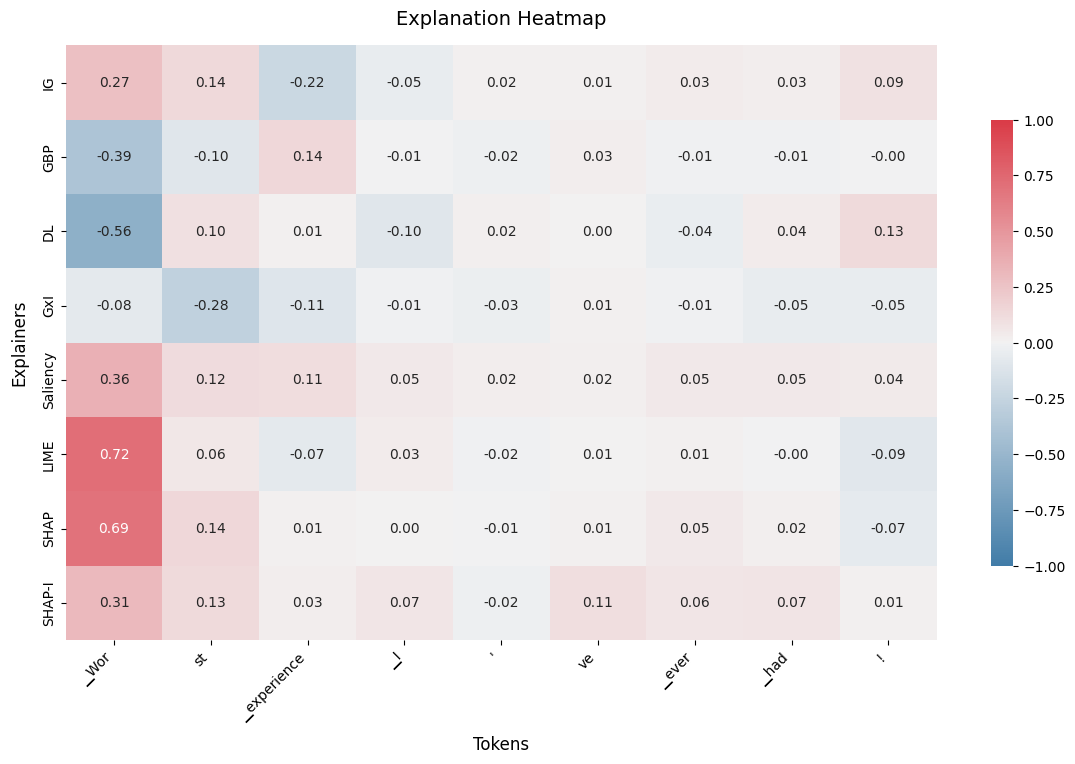

In [9]:
xai_framework.visualize(exps)

Step 6: Interpret and understand scores by LLM generated textual explanations

In [12]:
from LLMExplanationGenerator import LLMExplanationGenerator
import pandas as pd
from IPython.display import display, HTML

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = LLMExplanationGenerator(api_key=api_key)

# Generate and save explanations (returns both explanations and file paths)
explanations, saved_files = explainer.generate_and_save_explanations(
    exps=exps,
    output_format="both"  # or "json"/"html"
)

# Display in notebook
explainer.display_explanations(explanations)

# Print saved locations
print(f"Saved files: {[str(p) for p in saved_files]}")


Generating explanation for Integrated Gradients...
Generating explanation for Guided Backprop...
Generating explanation for DeepLift...
Generating explanation for Gradient×Input...
Generating explanation for Saliency...
Generating explanation for LIME...
Generating explanation for SHAP...
Generating explanation for SHAP-I...
file saved in ..\results\llm_explanations\explanations.html


Saved files: ['..\\results\\llm_explanations\\explanations.json', '..\\results\\llm_explanations\\explanations.html']


Step 6: Evaluate the explanations

You can evaluate explanations from different explainers initialized during the creation of the `XAIBenchmark` class using the `evaluate_single_sentence` function.

- If you provide a **human rationale**, **plausibility metrics** will be calculated.  
- If no rationale is provided, plausibility metrics **will not** be included.  

In [13]:
metrics=xai_framework.evaluate_single_sentence(sentence, target_label="negative",human_rationale=[1,0, 0, 1, 0,0,0,0,1,0,1,0])
xai_framework.create_pivot_table(metrics)

Running Inference: 100%|██████████| 25/25 [00:08<00:00,  3.02it/s]


Evaluator,Soft Comprehensiveness ↑,Soft Sufficiency ↓,AUTPC ↓,FAD ↓,Complexity ↓,Sparseness ↑,IOU F1 score ↑,Token F1 score ↑,AUPRC ↑
Explainer,,,,,,,,,
DL,0.588158,0.000206,0.400000,0.250000,0.130875,0.511543,0.750000,0.857143,0.496032
GBP,0.588158,0.457852,1.000000,0.250000,0.158059,0.430139,0.166667,0.285714,0.291667
GxI,0.588134,0.216042,0.500000,1.000000,0.179923,0.317123,0.400000,0.571429,0.299206
IG,0.588158,0.000206,0.200000,0.250000,0.183270,0.298697,0.400000,0.571429,0.637897
LIME,0.456629,0.000166,0.100000,0.250000,0.098990,0.592504,0.166667,0.285714,0.599206
SHAP,0.576707,0.000168,0.300000,0.250000,0.099601,0.599495,0.400000,0.571429,0.505952
SHAP-I,0.588140,0.000165,0.300000,0.250000,0.188502,0.256025,0.400000,0.571429,0.582341
Saliency,0.456629,0.000165,0.500000,0.250000,0.185589,0.257243,0.166667,0.285714,0.568651


Step 7: Interpret and understand metrics by LLM generated textual explanations

In [19]:
from EvaluationMetricsExplainer import EvaluationMetricsExplainer

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = EvaluationMetricsExplainer(api_key=api_key)

results = explainer.explain_results(metrics)
json_path, html_path = explainer.save_results(results)

explainer.display_results(results)

8
Metric        AUPRC ↑
Explainer          DL
Value        0.496032
Name: 8, dtype: object
DeepLift
Metric        AUPRC ↑
Explainer         GBP
Value        0.291667
Name: 17, dtype: object
Guided Backprop
Metric        AUPRC ↑
Explainer         GxI
Value        0.299206
Name: 26, dtype: object
Gradient×Input
Metric        AUPRC ↑
Explainer          IG
Value        0.637897
Name: 35, dtype: object
Integrated Gradients
Metric        AUPRC ↑
Explainer        LIME
Value        0.599206
Name: 44, dtype: object
LIME
Metric        AUPRC ↑
Explainer        SHAP
Value        0.505952
Name: 53, dtype: object
SHAP
Metric        AUPRC ↑
Explainer      SHAP-I
Value        0.582341
Name: 62, dtype: object
SHAP-I
Metric        AUPRC ↑
Explainer    Saliency
Value        0.568651
Name: 71, dtype: object
Saliency
Metric       AUTPC ↓
Explainer         DL
Value            0.4
Name: 5, dtype: object
DeepLift
Metric       AUTPC ↓
Explainer        GBP
Value            1.0
Name: 14, dtype: object
Guided Bac

Alternatively, you can use each evaluator’s `compute` function to assess individual metrics.  
For **plausibility metrics**, make sure to **add a rationale** to the explanation object before evaluation.

In [14]:
ig_exps.rationale= [0, 1, 0, 1, 0,0,0,0,1,0,1,0]
iou_f1.compute(ig_exps)
auprc.compute(ig_exps)

np.float64(0.26279761904761906)

#### Dataset

Step 1: Load the model and tokenizer

In [15]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

Step 2: Load the dataset

You can load any text classification dataset using the `load_fields_from_dataset` function, provided you specify the `LoadDatasetArgs` as follows:  
- **`dataset_name`** - The field containing dataset name on huggingface/ "csv", "json", etc for local files
- **`input_text_field`** – The field containing the text data.  
- **`label_field`** – The field containing the class labels.  
- **`rationale_field`** (optional) – The field marking important tokens in the text.
- **`dataset_files`** (optional) - The field containing filepath to a local csv/excel file e.g. ["healthFC_annotated.csv"]

HuggingFace Dataset

In [20]:
from dataset_loaders.dataset_loader import LoadDatasetArgs,load_fields_from_dataset

dataset_args_ = LoadDatasetArgs(
    dataset_name="eraser-benchmark/movie_rationales",
    text_field="review",
    label_field="label",
    rationale_field="evidences",
    dataset_split="test",
)

# Load the dataset fields
results = load_fields_from_dataset(dataset_args_)

Loading dataset...


In [21]:
input_texts= results['text']
labels= results['labels']
rationales= results['rationales']
input_texts[0], labels[0], rationales[0]

("there may not be a critic alive who harbors as much affection for shlock monster movies as i do .\ni delighted in the sneaky - smart entertainment of ron underwood 's big - underground - worm yarn tremors ; i even giggled at last year 's critically - savaged big - underwater - snake yarn anaconda .\nsomething about these films causes me to lower my inhibitions and return to the saturday afternoons of my youth , spent in the company of ghidrah , the creature from the black lagoon and the blob .\ndeep rising , a big - undersea - serpent yarn , does n't quite pass the test .\nsure enough , all the modern monster movie ingredients are in place : a conspicuously multi - ethnic / multi - national collection of bait .\n.. excuse me , characters ; an isolated location , here a derelict cruise ship in the south china sea ; some comic relief ; a few cgi - enhanced gross - outs ; and at least one big explosion .\nthere are too - cheesy - to - be - accidental elements , like a sleazy shipping ma

Local CSV File Dataset

In [19]:
# dataset_args_csv = LoadDatasetArgs(
#     dataset_name="csv",
#     text_field="en_text",
#     label_field="label",
#     rationale_field="en_explanation",
#     dataset_split="train",
#     dataset_files=["healthFC_annotated.csv"]
# )

# # Load the dataset fields
# results = load_fields_from_dataset(dataset_args_)

Loading dataset...


Expected Outputs:

- **`input_texts`** → An array of strings (text samples).  
- **`labels`** → An array of strings (corresponding class labels).  
- **`rationale`** → An array of binary values (`0` or `1`), indicating which tokens in the text are important.  

*You can preprocess or postprocess the data to ensure it is in the expected format if needed.*

In [22]:
from dataset_loaders.movie_rationales import MovieRationalesProcessor

mv= MovieRationalesProcessor(tokenizer)
processed_rationales= mv.process_dataset(input_texts, labels, rationales)

Select a sub-sample of the dataset

In [23]:
#Select a sub-sample if you want
input_texts_sample=results['text'][:2]
labels_sample=results['labels'][:2]
rationale_sample= processed_rationales[:2]

Step 3: Generate Explanations

In [30]:
exp_scores= xai_framework.get_feature_importance_for_dataset(input_texts_sample,labels_sample,rationale_sample,output_file="../results/scores/movie_04_02.json")

Processing instance 0
Found cached explanation for Saliency
Processing instance 1
Found cached explanation for Saliency
Saved explanations to ../results/scores/movie_04_02.json


Step 4: Interpret and understand scores by LLM generated textual explanations

In [25]:
from LLMExplanationGenerator import LLMExplanationGenerator
import pandas as pd
from IPython.display import display, HTML

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = LLMExplanationGenerator(api_key=api_key)

# Generate and save explanations (returns both explanations and file paths)
explanations, saved_files = explainer.generate_and_save_explanations(
    exps=exp_scores,
    output_format="both"  # or "json"/"html"
)

# Display in notebook
explainer.display_explanations(explanations)

# Print saved locations
print(f"Saved files: {[str(p) for p in saved_files]}")


file saved in ..\results\llm_explanations\explanations.html


Saved files: ['..\\results\\llm_explanations\\explanations.json', '..\\results\\llm_explanations\\explanations.html']


Step 5: Evaluate Explanations and generate table 

In [26]:
metrics= xai_framework.compute_evaluation_metrics(exp_scores)
xai_framework.create_pivot_table(metrics)


Explainer: Saliency
Computing value for Complexity ↓
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for FAD ↓
Computing value for Sparseness ↑
Computing value for AUTPC ↓


Evaluator,Soft Comprehensiveness ↑,Soft Sufficiency ↓,AUTPC ↓,FAD ↓,Complexity ↓,Sparseness ↑
Explainer,,,,,,
Saliency,0.255827,0.001541,0.250000,1.000000,0.011881,0.289792


Step 6: Interpret and understand metrics by LLM generated textual explanations

In [33]:
from EvaluationMetricsExplainer import EvaluationMetricsExplainer

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = EvaluationMetricsExplainer(api_key=api_key)

results = explainer.explain_results(metrics)
json_path, html_path = explainer.save_results(results)

explainer.display_results(results)

You can also do `Step 3` and `Step 5` of generating explanations and evaluating them together within a single function call.

In [35]:
eval_metrics= xai_framework.benchmark_dataset(input_texts_sample, labels_sample,rationales=rationale_sample)

Processing instance 0
Found cached explanation for Saliency
Processing instance 1
Found cached explanation for Saliency

Explainer: Saliency
Computing value for Complexity ↓
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for FAD ↓
Computing value for Sparseness ↑
Computing value for AUTPC ↓


In [36]:
xai_framework.create_pivot_table(eval_metrics)

Evaluator,Soft Comprehensiveness ↑,Soft Sufficiency ↓,AUTPC ↓,FAD ↓,Complexity ↓,Sparseness ↑
Explainer,,,,,,
Saliency,0.286620,0.001537,0.250000,1.000000,0.011881,0.289792
